# Hyperparameter Study for the Bias-Calibration Models

This notebook is the companion to `EDA_CALIBRATION_notebook_IDRISSI_FINAL.ipynb`: it documents **how** the hyperparameters used there were chosen, instead of hardcoding numbers that "seemed reasonable".

**Why a separate notebook:**
- The main notebook trains 4 configurations × up to 8 weather models × 2 variables. Running a full hyperparameter search for every combination would multiply the runtime by 10-20x.
- A hyperparameter search is exploratory work. It does not belong in the main notebook, which should read as a clean, linear story.
- Keeping it separate makes the results traceable: this notebook can be re-run on its own.

**What we do here:**
1. Tune MLP, SVR, Random Forest and LightGBM for **Config A** and **Config B**, for t2m, using **Optuna** (Bayesian/TPE search).
2. Check that the best hyperparameters found on AIFS also help on other models (generalization check).
3. Do the same for the tp06 classifier (SVC, MLPClassifier, RandomForestClassifier, LGBMClassifier).
4. Summarize the final recommended hyperparameters.

**Why Optuna instead of RandomizedSearchCV:** Optuna's TPE sampler uses the scores of earlier trials to decide where to sample next. For the same number of trials, this reaches a better result than pure random sampling. LightGBM's search also uses pruning (stopping bad trials early after the first CV fold), which saves compute.

**Why TimeSeriesSplit:** the main notebook uses a chronological train/test split (oldest 80% / newest 20%) because shuffling would leak future information. The same logic applies here: `TimeSeriesSplit` ensures each validation fold only uses data from *after* the training fold.

**A note on SVR/SVC:** SVMs scale poorly with the number of training rows (~O(n²)), so SVR/SVC searches use fewer trials than the tree-based models. SVR/SVC also need standardized features (like the MLP), since they rely on distances between feature vectors.


## Step 0: Setup — reload and re-derive exactly the same features as the main notebook

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', 200)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.svm import SVR, SVC
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import precision_score, recall_score, f1_score

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)  # silence per-trial logs; we print our own summary

# LightGBM is an optional dependency (not part of scikit-learn). If it's missing in this
# environment, fail with a clear instruction instead of a confusing ImportError deep in a cell.
try:
    from lightgbm import LGBMRegressor, LGBMClassifier
    LIGHTGBM_AVAILABLE = True
except ImportError:
    LIGHTGBM_AVAILABLE = False
    print("lightgbm is not installed. Run `pip install lightgbm` to enable the LGBM sections "
          "of this notebook; the rest of the notebook will still run without it.")

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*Maximum iterations.*")

os.makedirs("../results/tables", exist_ok=True)
os.makedirs("../results/figures", exist_ok=True)

RANDOM_STATE = 42


In [2]:
# Same loading + feature engineering as the main notebook (Part 1, Step 1 and Step 18)
df = pd.read_csv('../data/dataset_fusionnée.csv')
df = df[df['model'] != 'arome'].copy()   # AROME is handled separately, see main notebook

df['valid_time'] = pd.to_datetime(df['valid_time'])
df['hour'] = df['valid_time'].dt.hour
df['month'] = df['valid_time'].dt.month

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["is_afternoon"] = (df["hour"] == 12).astype(int)
df["is_night"] = df["hour"].isin([0, 6]).astype(int)

BASE_FEATURES = ["lat", "lon", "lead_time", "hour_sin", "hour_cos", "is_afternoon", "is_night"]
FEATURES = ["pred_value"] + BASE_FEATURES

print("Rows:", len(df))
print("Models:", sorted(df['model'].unique()))
print("Number of features:", len(FEATURES))
df[FEATURES + ["biais"]].head()


Rows: 261082
Models: ['aifs', 'aurora', 'dlwp', 'fengwu', 'fourcastnet', 'fuxi', 'graphcast', 'pangu6']
Number of features: 8


,pred_value,lat,lon,lead_time,hour_sin,hour_cos,is_afternoon,is_night,biais
0,20.277063,27.25,-13.25,0,0.0,1.0,0,1,-1.522937
1,19.077051,29.25,-10.25,0,0.0,1.0,0,1,-0.522949
2,22.777063,35.75,-6.00,0,0.0,1.0,0,1,-0.522937
3,21.477045,35.25,-6.00,0,0.0,1.0,0,1,-1.022955
4,21.877039,35.25,-3.75,0,0.0,1.0,0,1,2.577039


In [3]:
# Same helper functions as the main notebook (Part 2, Steps 4-5 and 7), copied here so this
# notebook is fully self-contained and does not depend on the main notebook having been run first.

def split_train_test(table, test_fraction=0.2):
    table = table.sort_values("valid_time")
    n_rows = len(table)
    n_train = int(n_rows * (1 - test_fraction))
    return table.iloc[:n_train].copy(), table.iloc[n_train:].copy()


def get_scores(real_values, predicted_values):
    mae = mean_absolute_error(real_values, predicted_values)
    rmse = np.sqrt(mean_squared_error(real_values, predicted_values))
    r2 = r2_score(real_values, predicted_values)
    return {"MAE": round(mae, 3), "RMSE": round(rmse, 3), "R2": round(r2, 3)}


def compare_to_baseline(test_table, predicted_bias, pred_column="pred_value"):
    real_obs = test_table["obs_value"]
    raw_forecast = test_table[pred_column]
    corrected_forecast = test_table[pred_column] - predicted_bias

    raw_rmse = np.sqrt(mean_squared_error(real_obs, raw_forecast))
    corrected_rmse = np.sqrt(mean_squared_error(real_obs, corrected_forecast))
    rmse_improvement_pct = (1 - corrected_rmse / raw_rmse) * 100 if raw_rmse > 0 else np.nan

    return {
        "raw_RMSE": round(raw_rmse, 3),
        "corrected_RMSE": round(corrected_rmse, 3),
        "RMSE_improvement_pct": round(rmse_improvement_pct, 1),
    }


def get_variable_predictions(weather_model, variable):
    part = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    part = part[["station", "run_time", "lead_time", "pred_value"]].copy()
    return part.rename(columns={"pred_value": "pred_" + variable})


def get_other_variables(weather_model, target_variable):
    model_variables = df[df["model"] == weather_model]["variable_name"].unique()
    return [v for v in model_variables if v != target_variable]


def build_multi_parameter_table(weather_model, target_variable, other_variables):
    target_part = df[(df["model"] == weather_model) & (df["variable_name"] == target_variable)].copy()
    target_pred_col = "pred_" + target_variable
    target_part = target_part.rename(columns={"pred_value": target_pred_col})

    wide_table = target_part
    for other_var in other_variables:
        other_part = get_variable_predictions(weather_model, other_var)
        wide_table = wide_table.merge(other_part, on=["station", "run_time", "lead_time"], how="left")

    other_pred_cols = ["pred_" + v for v in other_variables]
    wide_table = wide_table.sort_values(["station", "run_time", "lead_time"])
    wide_table[other_pred_cols] = wide_table.groupby(["station", "run_time"])[other_pred_cols].ffill()
    wide_table[other_pred_cols] = wide_table.groupby(["station", "run_time"])[other_pred_cols].bfill()

    multi_features = [target_pred_col] + other_pred_cols + BASE_FEATURES
    needed_cols = list(set(multi_features + ["obs_value", "biais"]))
    wide_table = wide_table.dropna(subset=needed_cols)

    return wide_table, multi_features


def balance_classes(features_df, labels, random_state=42):
    """Random oversampling of the minority class in the training data (see main notebook, Step 8)."""
    features_df = features_df.reset_index(drop=True)
    labels = labels.reset_index(drop=True)
    rng = np.random.RandomState(random_state)
    idx_pos = labels[labels == 1].index.to_numpy()
    idx_neg = labels[labels == 0].index.to_numpy()
    if len(idx_pos) == 0 or len(idx_neg) == 0:
        return features_df, labels
    n_target = max(len(idx_pos), len(idx_neg))
    idx_pos_bal = rng.choice(idx_pos, size=n_target, replace=True)
    idx_neg_bal = rng.choice(idx_neg, size=n_target, replace=True)
    idx_bal = np.concatenate([idx_pos_bal, idx_neg_bal])
    rng.shuffle(idx_bal)
    return features_df.loc[idx_bal].reset_index(drop=True), labels.loc[idx_bal].reset_index(drop=True)


class OptunaSearchResult:
    """Thin adapter so downstream cells can keep using `.best_params_` / `.best_score_`,
    the same attribute names `RandomizedSearchCV` exposed, without rewriting every cell that
    consumes a search result (Step 4, Step 6, Step 6b)."""
    def __init__(self, study, fixed_params=None):
        self.study = study
        self.best_params_ = {**(fixed_params or {}), **study.best_params}
        self.best_score_ = study.best_value
        self.trials_dataframe = study.trials_dataframe


def run_optuna_search(objective, n_trials, direction="maximize", seed=RANDOM_STATE,
                       fixed_params=None, pruner=None, label=""):
    """Run an Optuna study and return an OptunaSearchResult with sklearn-compatible attributes.

    `objective(trial)` must return the scalar to optimize (we use CV score directly, so
    direction="maximize" for both neg-MSE and F1, matching how RandomizedSearchCV's `scoring`
    argument treats them).
    """
    sampler = optuna.samplers.TPESampler(seed=seed)
    study = optuna.create_study(direction=direction, sampler=sampler, pruner=pruner)
    t0 = time.time()
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    elapsed = time.time() - t0
    result = OptunaSearchResult(study, fixed_params=fixed_params)
    print(f"{label} search done in {elapsed:.0f}s ({n_trials} trials)")
    print("Best params:", result.best_params_)
    print("Best CV score:", round(result.best_score_, 4))
    return result


## Step 1: Pick a representative model to run the search on

Running a full hyperparameter search on all 8 models for both configs would take a long time for very
little extra insight, since the models mostly differ in RMSE magnitude, not in what
hyperparameters work well. We tune on **AIFS**: it's the model with the most training rows
(after AROME, it has the largest sample size), it's the model the reference report and our own
EDA (Part 1) flag as benefiting the most from calibration, and it's the model the main notebook's
best result (R²=0.727) comes from. Section 4 below checks that the hyperparameters found here
also help on other models, so we are not just overfitting the search to AIFS's specific noise
level.


In [4]:
ai_models = sorted(df[df["variable_name"] == "t2m"]["model"].unique())
print("Available models:", ai_models)

TUNE_MODEL = "aifs"
subset_single = df[(df["model"] == TUNE_MODEL) & (df["variable_name"] == "t2m")]
train_single, test_single = split_train_test(subset_single)
print(f"{TUNE_MODEL} single-variable t2m: {len(train_single)} train rows, {len(test_single)} test rows")


Available models: ['aifs', 'aurora', 'dlwp', 'fengwu', 'fourcastnet', 'fuxi', 'graphcast', 'pangu6']
aifs single-variable t2m: 19688 train rows, 4923 test rows


## Step 2: Config A (single-variable) — tuning all four algorithms

Search spaces:

- **MLPRegressor**: `hidden_layer_sizes`, `activation`, `alpha`, `learning_rate_init`. Searched on standardized features.
- **SVR**: `C`, `epsilon`, `kernel` (rbf/linear), `gamma` (only sampled when kernel=rbf). Also on standardized features.
- **RandomForestRegressor**: `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features`, `max_samples`. Searched on raw (unscaled) features.
- **LGBMRegressor**: `n_estimators`, `max_depth`, `learning_rate`, `num_leaves`, `subsample`, `min_child_samples`, `colsample_bytree`, `reg_alpha`, `reg_lambda`. Also unscaled. Uses Optuna's `MedianPruner` to stop bad trials early.

All four scored with negative MSE via 3-fold `TimeSeriesSplit`. Search budget: MLP 30 trials, SVR 25 trials, Random Forest and LGBM 40 trials each.


In [5]:
x_scaler_A = StandardScaler().fit(train_single[FEATURES])
y_scaler_A = StandardScaler().fit(train_single[["biais"]])
x_train_A = x_scaler_A.transform(train_single[FEATURES])
y_train_A = y_scaler_A.transform(train_single[["biais"]]).ravel()

tscv = TimeSeriesSplit(n_splits=3)

MLP_ARCHITECTURES = [(16,), (32,), (32, 16), (64, 32), (16, 8), (64, 32, 16)]

def objective_mlp(trial, X, y):
    params = {
        "hidden_layer_sizes": MLP_ARCHITECTURES[trial.suggest_int("hidden_layer_sizes_idx", 0, len(MLP_ARCHITECTURES) - 1)],
        "activation": trial.suggest_categorical("activation", ["relu", "tanh"]),
        "alpha": trial.suggest_float("alpha", 1e-5, 1e-1, log=True),
        "learning_rate_init": trial.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True),
    }
    scores = []
    for train_idx, val_idx in tscv.split(X):
        model = MLPRegressor(max_iter=300, early_stopping=True, random_state=RANDOM_STATE, **params)
        model.fit(X[train_idx], y[train_idx])
        pred = model.predict(X[val_idx])
        scores.append(-mean_squared_error(y[val_idx], pred))  # negative MSE, so higher = better
    return float(np.mean(scores))


search_mlp_A = run_optuna_search(
    lambda trial: objective_mlp(trial, x_train_A, y_train_A),
    n_trials=30, label="MLP Config A",
)
# Translate the architecture index back into the actual tuple, matching RandomizedSearchCV's
# best_params_ format (a literal hidden_layer_sizes tuple).
search_mlp_A.best_params_["hidden_layer_sizes"] = MLP_ARCHITECTURES[search_mlp_A.best_params_.pop("hidden_layer_sizes_idx")]
print("Best params (translated):", search_mlp_A.best_params_)


MLP Config A search done in 368s (30 trials)
Best params: {'hidden_layer_sizes_idx': 3, 'activation': 'tanh', 'alpha': 0.0002920433847181409, 'learning_rate_init': 0.000816845589476017}
Best CV score: -0.4137
Best params (translated): {'activation': 'tanh', 'alpha': 0.0002920433847181409, 'learning_rate_init': 0.000816845589476017, 'hidden_layer_sizes': (64, 32)}


In [6]:
# SVR needs scaled features (same reasoning, and the same scaler, as the MLP above).

def objective_svr(trial, X, y):
    kernel = trial.suggest_categorical("kernel", ["rbf", "linear"])
    params = {
        "C": trial.suggest_float("C", 1e-1, 1e3, log=True),
        "epsilon": trial.suggest_float("epsilon", 1e-3, 1.0, log=True),
        "kernel": kernel,
    }
    if kernel == "rbf":
        params["gamma"] = trial.suggest_float("gamma", 1e-4, 1e0, log=True)
    scores = []
    for train_idx, val_idx in tscv.split(X):
        model = SVR(**params)
        model.fit(X[train_idx], y[train_idx])
        pred = model.predict(X[val_idx])
        scores.append(-mean_squared_error(y[val_idx], pred))
    return float(np.mean(scores))


search_svr_A = run_optuna_search(
    lambda trial: objective_svr(trial, x_train_A, y_train_A),
    n_trials=25, label="SVR Config A",
)


SVR Config A search done in 970s (25 trials)
Best params: {'kernel': 'rbf', 'C': 0.29663272054469436, 'epsilon': 0.48277125473350574, 'gamma': 0.07848845094209282}
Best CV score: -0.4372


In [7]:
def objective_rf(trial, X, y):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "max_depth": trial.suggest_int("max_depth", 3, 25),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 40),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 50),
        "max_features": trial.suggest_float("max_features", 0.3, 1.0),
        "max_samples": trial.suggest_float("max_samples", 0.5, 1.0),
    }
    scores = []
    for train_idx, val_idx in tscv.split(X):
        model = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, bootstrap=True, **params)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[val_idx])
        scores.append(-mean_squared_error(y.iloc[val_idx], pred))
    return float(np.mean(scores))


search_rf_A = run_optuna_search(
    lambda trial: objective_rf(trial, train_single[FEATURES], train_single["biais"]),
    n_trials=40, label="Random Forest Config A",
)


Random Forest Config A search done in 57s (40 trials)
Best params: {'n_estimators': 179, 'max_depth': 22, 'min_samples_split': 5, 'min_samples_leaf': 10, 'max_features': 0.36036833842338895, 'max_samples': 0.6018991761512245}
Best CV score: -9.363


In [8]:
def objective_lgbm(trial, X, y):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 600),
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 200),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 80),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
    }
    scores = []
    for fold_idx, (train_idx, val_idx) in enumerate(tscv.split(X)):
        model = LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **params)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[val_idx])
        fold_score = -mean_squared_error(y.iloc[val_idx], pred)
        scores.append(fold_score)
        # Report the running mean after each fold so the MedianPruner can stop clearly weak
        # trials early instead of always running all 3 folds.
        trial.report(float(np.mean(scores)), fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return float(np.mean(scores))


if LIGHTGBM_AVAILABLE:
    search_lgbm_A = run_optuna_search(
        lambda trial: objective_lgbm(trial, train_single[FEATURES], train_single["biais"]),
        n_trials=40, label="LGBM Config A",
        pruner=optuna.pruners.MedianPruner(n_warmup_steps=1),
    )
else:
    search_lgbm_A = None
    print("Skipping LGBM Config A search: lightgbm is not installed.")


LGBM Config A search done in 49s (40 trials)
Best params: {'n_estimators': 250, 'max_depth': 12, 'learning_rate': 0.011451844802259338, 'num_leaves': 88, 'subsample': 0.6745275586556285, 'min_child_samples': 60, 'colsample_bytree': 0.75261120564501, 'reg_alpha': 0.003295732159059646, 'reg_lambda': 0.0060924058597702615}
Best CV score: -9.1673


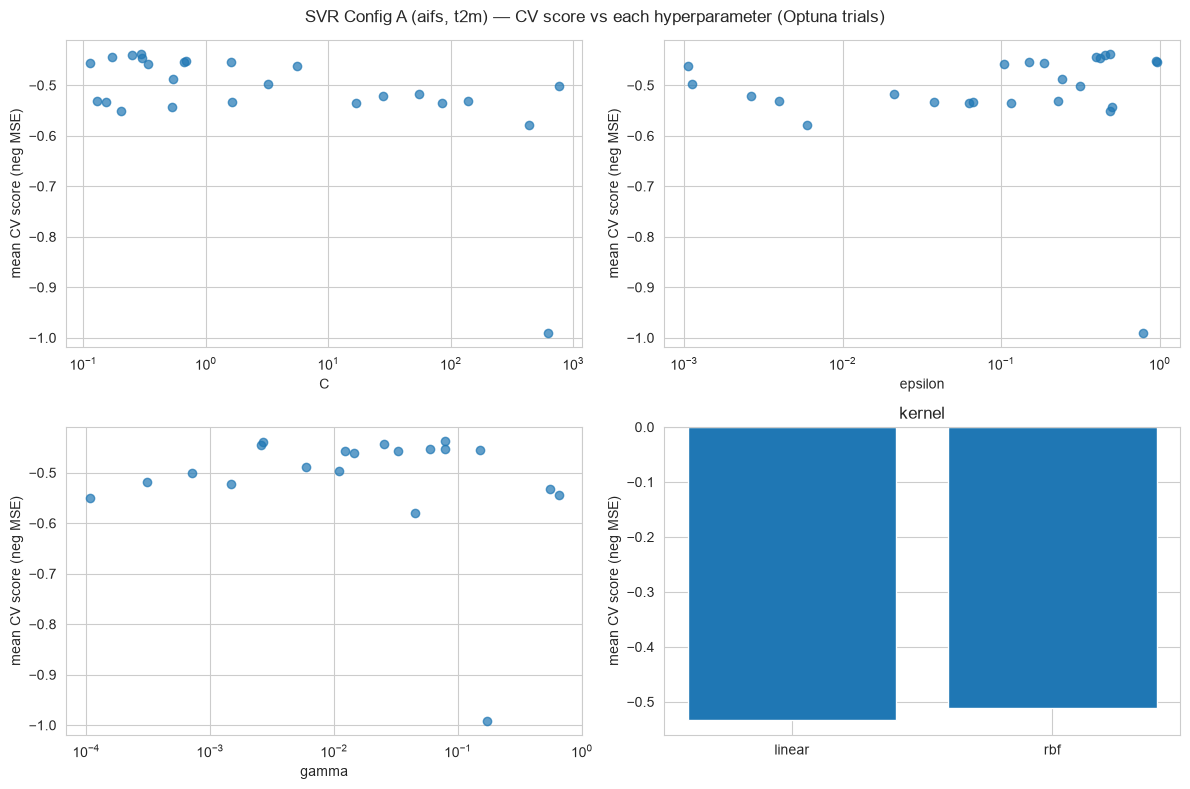

In [9]:
# Visualize how the CV score depends on each hyperparameter, to justify the choice
# beyond just quoting best_params_ (this is the "proof" the supervisor is asking for).
# Optuna's study.trials_dataframe() gives one row per trial with columns like
# "params_<name>" and "value" (the objective score) -- we rename to match the
# "param_<name>" / "mean_test_score" convention the previous RandomizedSearchCV-based
# plotting code used, so the same plotting helper works unchanged for both search backends.

def trials_to_cv_results(study_result):
    tdf = study_result.trials_dataframe()
    tdf = tdf[tdf["state"] == "COMPLETE"].copy()
    tdf = tdf.rename(columns={c: c.replace("params_", "param_") for c in tdf.columns if c.startswith("params_")})
    tdf["mean_test_score"] = tdf["value"]
    return tdf


def plot_param_vs_score(cv_results, param_name, ax, log_x=False):
    col = f"param_{param_name}"
    values = cv_results[col]
    try:
        values = values.astype(float)
    except (TypeError, ValueError):
        values = values.astype(str)
    scores = cv_results["mean_test_score"]
    ax.scatter(values, scores, alpha=0.7)
    ax.set_xlabel(param_name)
    ax.set_ylabel("mean CV score (neg MSE)")
    if log_x:
        ax.set_xscale("log")


cv_res_svr_A = trials_to_cv_results(search_svr_A.study)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
plot_param_vs_score(cv_res_svr_A, "C", axes[0], log_x=True)
plot_param_vs_score(cv_res_svr_A, "epsilon", axes[1], log_x=True)
if "param_gamma" in cv_res_svr_A.columns:
    plot_param_vs_score(cv_res_svr_A, "gamma", axes[2], log_x=True)
else:
    axes[2].axis("off")
kernel_scores = cv_res_svr_A.groupby("param_kernel")["mean_test_score"].mean()
axes[3].bar(kernel_scores.index, kernel_scores.values)
axes[3].set_ylabel("mean CV score (neg MSE)")
axes[3].set_title("kernel")
plt.suptitle(f"SVR Config A ({TUNE_MODEL}, t2m) — CV score vs each hyperparameter (Optuna trials)")
plt.tight_layout()
plt.savefig("../results/figures/svr_single_hyperparam_search.png")
plt.show()


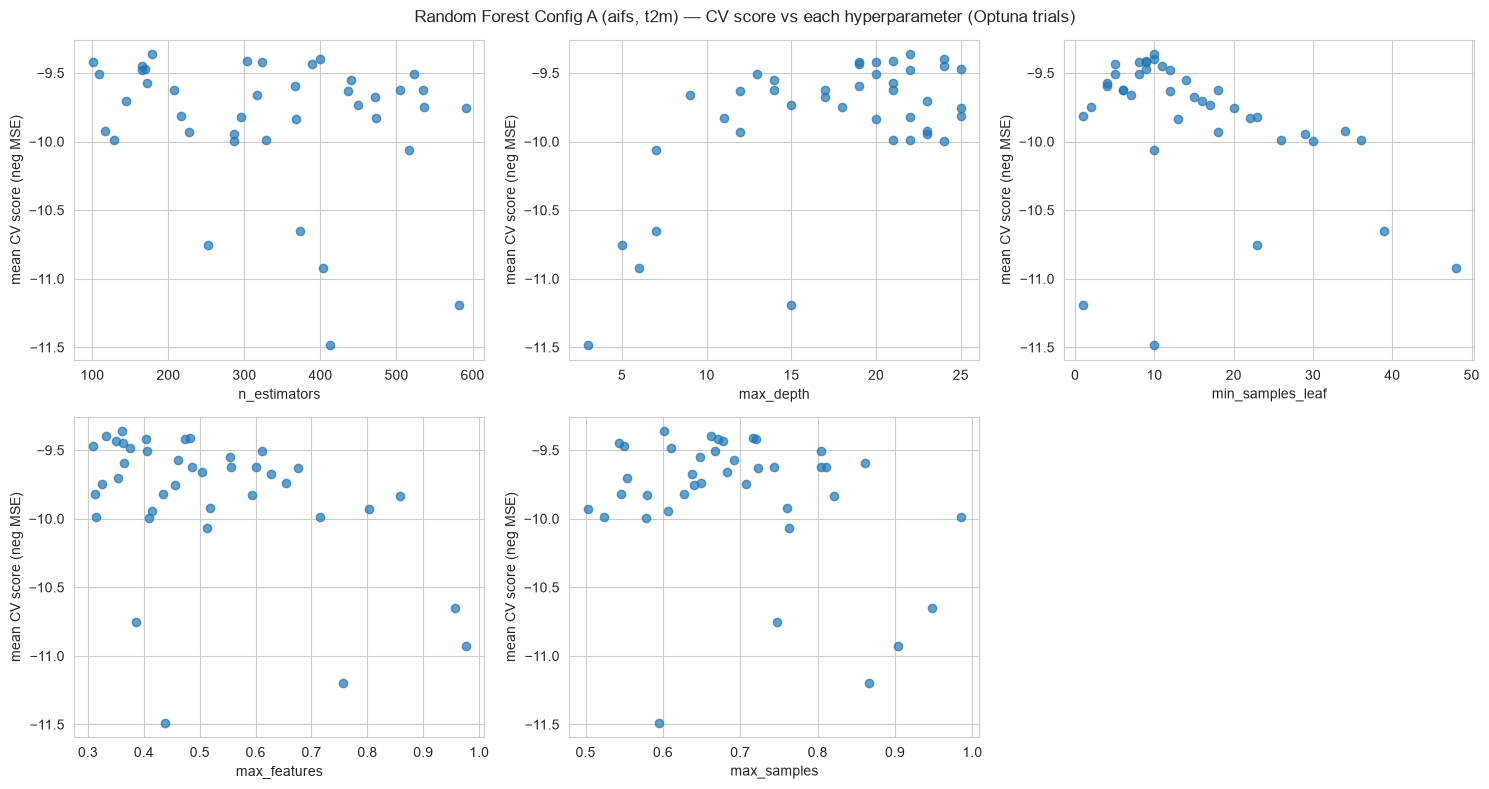

In [10]:
cv_res_rf_A = trials_to_cv_results(search_rf_A.study)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
plot_param_vs_score(cv_res_rf_A, "n_estimators", axes[0])
plot_param_vs_score(cv_res_rf_A, "max_depth", axes[1])
plot_param_vs_score(cv_res_rf_A, "min_samples_leaf", axes[2])
plot_param_vs_score(cv_res_rf_A, "max_features", axes[3])
plot_param_vs_score(cv_res_rf_A, "max_samples", axes[4])
axes[5].axis("off")
plt.suptitle(f"Random Forest Config A ({TUNE_MODEL}, t2m) — CV score vs each hyperparameter (Optuna trials)")
plt.tight_layout()
plt.savefig("../results/figures/rf_single_hyperparam_search.png")
plt.show()


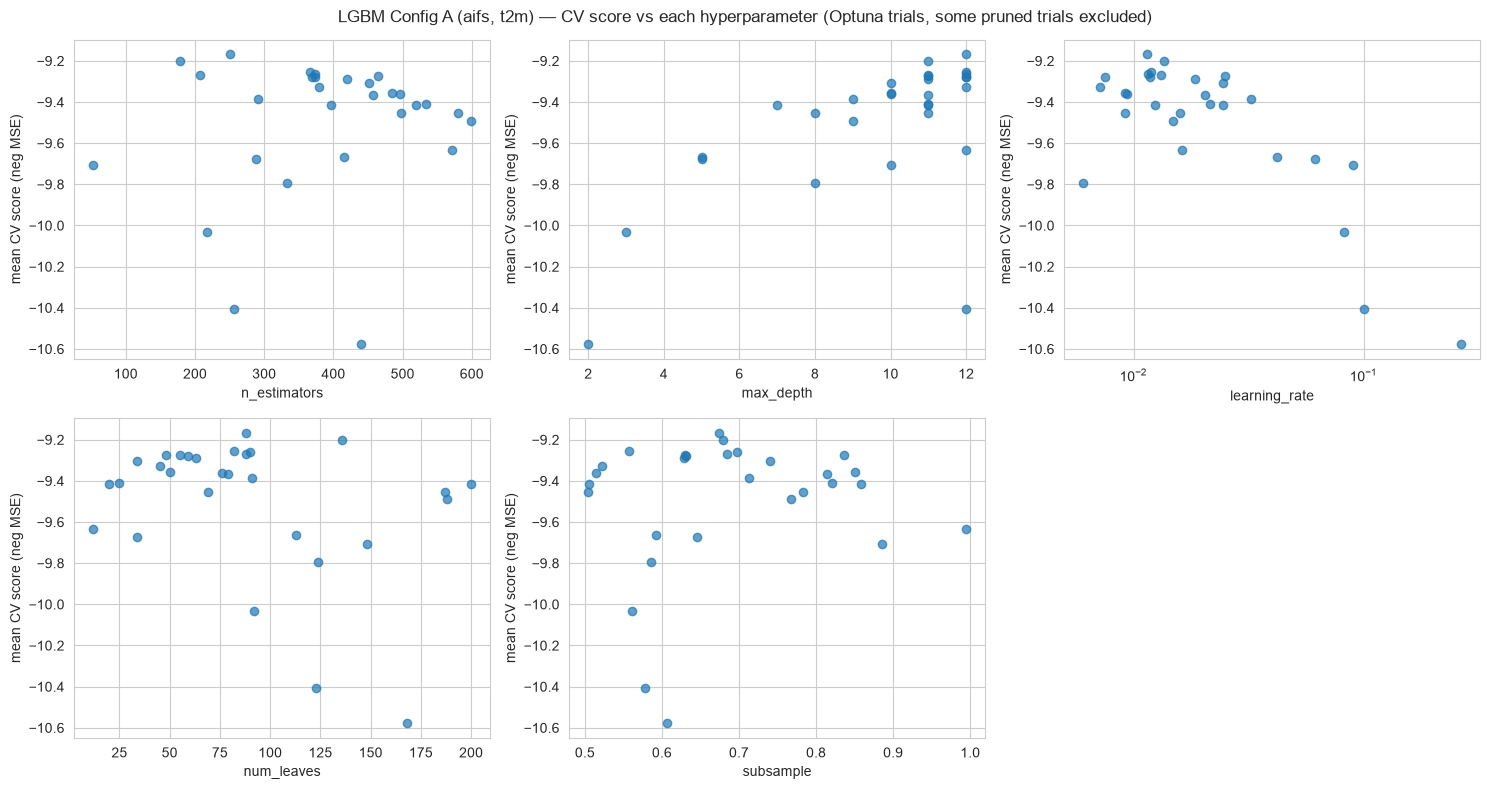

In [11]:
if LIGHTGBM_AVAILABLE:
    cv_res_lgbm_A = trials_to_cv_results(search_lgbm_A.study)

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()
    plot_param_vs_score(cv_res_lgbm_A, "n_estimators", axes[0])
    plot_param_vs_score(cv_res_lgbm_A, "max_depth", axes[1])
    plot_param_vs_score(cv_res_lgbm_A, "learning_rate", axes[2], log_x=True)
    plot_param_vs_score(cv_res_lgbm_A, "num_leaves", axes[3])
    plot_param_vs_score(cv_res_lgbm_A, "subsample", axes[4])
    axes[5].axis("off")
    plt.suptitle(f"LGBM Config A ({TUNE_MODEL}, t2m) — CV score vs each hyperparameter (Optuna trials, some pruned trials excluded)")
    plt.tight_layout()
    plt.savefig("../results/figures/lgbm_single_hyperparam_search.png")
    plt.show()
else:
    print("Skipping LGBM Config A plot: lightgbm is not installed.")


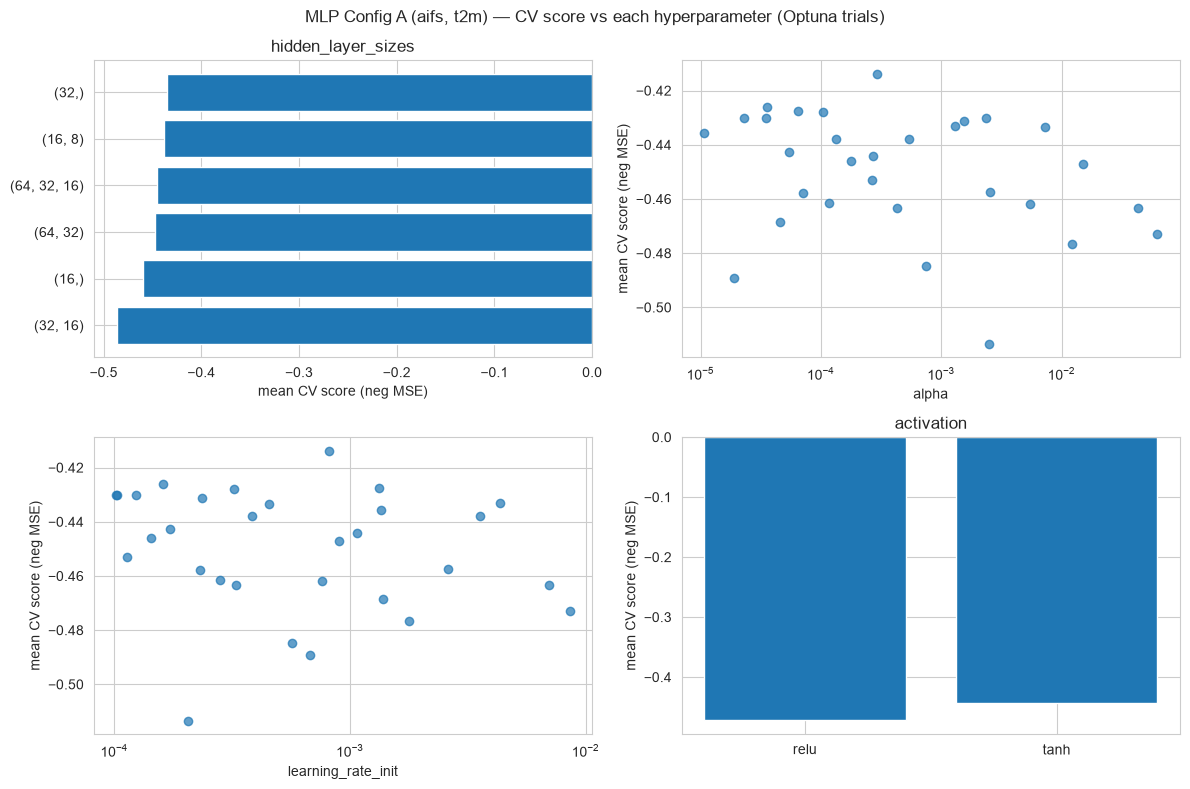

In [12]:
cv_res_mlp_A = trials_to_cv_results(search_mlp_A.study)
cv_res_mlp_A["param_hidden_layer_sizes_idx"] = cv_res_mlp_A["param_hidden_layer_sizes_idx"].astype(int)
cv_res_mlp_A["param_hidden_layer_sizes"] = cv_res_mlp_A["param_hidden_layer_sizes_idx"].map(
    lambda i: str(MLP_ARCHITECTURES[i])
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

# hidden_layer_sizes is categorical here: show as a bar chart of mean score per architecture
arch_scores = cv_res_mlp_A.groupby("param_hidden_layer_sizes")["mean_test_score"].mean().sort_values()
axes[0].barh(arch_scores.index, arch_scores.values)
axes[0].set_xlabel("mean CV score (neg MSE)")
axes[0].set_title("hidden_layer_sizes")

plot_param_vs_score(cv_res_mlp_A, "alpha", axes[1], log_x=True)
plot_param_vs_score(cv_res_mlp_A, "learning_rate_init", axes[2], log_x=True)
act_scores = cv_res_mlp_A.groupby("param_activation")["mean_test_score"].mean()
axes[3].bar(act_scores.index, act_scores.values)
axes[3].set_ylabel("mean CV score (neg MSE)")
axes[3].set_title("activation")

plt.suptitle(f"MLP Config A ({TUNE_MODEL}, t2m) — CV score vs each hyperparameter (Optuna trials)")
plt.tight_layout()
plt.savefig("../results/figures/mlp_single_hyperparam_search.png")
plt.show()


## Step 3: Config B (multi-parameter) — same search, richer feature set, all four algorithms

In [13]:
other_vars_aifs = get_other_variables(TUNE_MODEL, "t2m")
print("Extra variables available for AIFS:", other_vars_aifs)

wide_table_B, multi_features_B = build_multi_parameter_table(TUNE_MODEL, "t2m", other_vars_aifs)
train_multi, test_multi = split_train_test(wide_table_B)
print(f"Config B: {len(train_multi)} train rows, {len(multi_features_B)} features: {multi_features_B}")


Extra variables available for AIFS: ['msl', 'sp', 'td2m', 'tp06']
Config B: 842 train rows, 12 features: ['pred_t2m', 'pred_msl', 'pred_sp', 'pred_td2m', 'pred_tp06', 'lat', 'lon', 'lead_time', 'hour_sin', 'hour_cos', 'is_afternoon', 'is_night']


In [14]:
x_scaler_B = StandardScaler().fit(train_multi[multi_features_B])
y_scaler_B = StandardScaler().fit(train_multi[["biais"]])
x_train_B = x_scaler_B.transform(train_multi[multi_features_B])
y_train_B = y_scaler_B.transform(train_multi[["biais"]]).ravel()

search_mlp_B = run_optuna_search(
    lambda trial: objective_mlp(trial, x_train_B, y_train_B),
    n_trials=30, label="MLP Config B",
)
search_mlp_B.best_params_["hidden_layer_sizes"] = MLP_ARCHITECTURES[search_mlp_B.best_params_.pop("hidden_layer_sizes_idx")]
print("Best params (translated):", search_mlp_B.best_params_)


MLP Config B search done in 22s (30 trials)
Best params: {'hidden_layer_sizes_idx': 3, 'activation': 'tanh', 'alpha': 3.683436877306914e-05, 'learning_rate_init': 0.0017340750366137945}
Best CV score: -0.3619
Best params (translated): {'activation': 'tanh', 'alpha': 3.683436877306914e-05, 'learning_rate_init': 0.0017340750366137945, 'hidden_layer_sizes': (64, 32)}


In [15]:
search_svr_B = run_optuna_search(
    lambda trial: objective_svr(trial, x_train_B, y_train_B),
    n_trials=25, label="SVR Config B",
)


SVR Config B search done in 6s (25 trials)
Best params: {'kernel': 'rbf', 'C': 0.42665879101907306, 'epsilon': 0.48277125473350574, 'gamma': 0.05606621320697633}
Best CV score: -0.3706


In [16]:
search_rf_B = run_optuna_search(
    lambda trial: objective_rf(trial, train_multi[multi_features_B], train_multi["biais"]),
    n_trials=40, label="Random Forest Config B",
)


Random Forest Config B search done in 61s (40 trials)
Best params: {'n_estimators': 459, 'max_depth': 20, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 0.5829181279653138, 'max_samples': 0.9810323375633047}
Best CV score: -9.6948


In [17]:
if LIGHTGBM_AVAILABLE:
    search_lgbm_B = run_optuna_search(
        lambda trial: objective_lgbm(trial, train_multi[multi_features_B], train_multi["biais"]),
        n_trials=40, label="LGBM Config B",
        pruner=optuna.pruners.MedianPruner(n_warmup_steps=1),
    )
else:
    search_lgbm_B = None
    print("Skipping LGBM Config B search: lightgbm is not installed.")


LGBM Config B search done in 9s (40 trials)
Best params: {'n_estimators': 242, 'max_depth': 12, 'learning_rate': 0.006442086782554566, 'num_leaves': 30, 'subsample': 0.5318029776538943, 'min_child_samples': 6, 'colsample_bytree': 0.7525493115859065, 'reg_alpha': 0.001262593667142789, 'reg_lambda': 0.0031379313073400944}
Best CV score: -9.5648


## Step 4: Do the tuned hyperparameters generalize to other models?

The search above only looked at AIFS. Before trusting these hyperparameters for the whole project, we refit both a plain-default baseline and the tuned values, for all four algorithms, on 3 other models (`dlwp`, `graphcast`, `fengwu`) and compare test-set RMSE on the actual corrected forecast.


In [18]:
DEFAULT_MLP_PARAMS = dict(hidden_layer_sizes=(32, 16), max_iter=300, early_stopping=True, random_state=RANDOM_STATE)
DEFAULT_SVR_PARAMS = dict()                                             # plain sklearn defaults (kernel="rbf", C=1.0, epsilon=0.1)
DEFAULT_RF_PARAMS = dict(random_state=RANDOM_STATE, n_jobs=-1)          # plain sklearn defaults
DEFAULT_LGBM_PARAMS = dict(random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1)  # plain LightGBM defaults

TUNED_MLP_PARAMS = {**search_mlp_A.best_params_, "max_iter": 300, "early_stopping": True, "random_state": RANDOM_STATE}
TUNED_SVR_PARAMS = dict(search_svr_A.best_params_)   # SVR has no random_state parameter
TUNED_RF_PARAMS = {**search_rf_A.best_params_, "random_state": RANDOM_STATE, "n_jobs": -1, "bootstrap": True}
TUNED_LGBM_PARAMS = ({**search_lgbm_A.best_params_, "random_state": RANDOM_STATE, "n_jobs": -1, "verbosity": -1}
                      if LIGHTGBM_AVAILABLE else None)

print("Default MLP:", DEFAULT_MLP_PARAMS)
print("Tuned MLP:  ", TUNED_MLP_PARAMS)
print()
print("Default SVR:", DEFAULT_SVR_PARAMS)
print("Tuned SVR:  ", TUNED_SVR_PARAMS)
print()
print("Default RF:", DEFAULT_RF_PARAMS)
print("Tuned RF:  ", TUNED_RF_PARAMS)
print()
print("Default LGBM:", DEFAULT_LGBM_PARAMS)
print("Tuned LGBM:  ", TUNED_LGBM_PARAMS)


Default MLP: {'hidden_layer_sizes': (32, 16), 'max_iter': 300, 'early_stopping': True, 'random_state': 42}
Tuned MLP:   {'activation': 'tanh', 'alpha': 0.0002920433847181409, 'learning_rate_init': 0.000816845589476017, 'hidden_layer_sizes': (64, 32), 'max_iter': 300, 'early_stopping': True, 'random_state': 42}

Default SVR: {}
Tuned SVR:   {'kernel': 'rbf', 'C': 0.29663272054469436, 'epsilon': 0.48277125473350574, 'gamma': 0.07848845094209282}

Default RF: {'random_state': 42, 'n_jobs': -1}
Tuned RF:   {'n_estimators': 179, 'max_depth': 22, 'min_samples_split': 5, 'min_samples_leaf': 10, 'max_features': 0.36036833842338895, 'max_samples': 0.6018991761512245, 'random_state': 42, 'n_jobs': -1, 'bootstrap': True}

Default LGBM: {'random_state': 42, 'n_jobs': -1, 'verbosity': -1}
Tuned LGBM:   {'n_estimators': 250, 'max_depth': 12, 'learning_rate': 0.011451844802259338, 'num_leaves': 88, 'subsample': 0.6745275586556285, 'min_child_samples': 60, 'colsample_bytree': 0.75261120564501, 'reg_al

In [19]:
def fit_eval_mlp(weather_model, variable, params):
    subset = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    train, test = split_train_test(subset)
    xs = StandardScaler().fit(train[FEATURES]); ys = StandardScaler().fit(train[["biais"]])
    x_tr = xs.transform(train[FEATURES]); y_tr = ys.transform(train[["biais"]]).ravel()
    x_te = xs.transform(test[FEATURES])

    model = MLPRegressor(**params)
    model.fit(x_tr, y_tr)
    pred_scaled = model.predict(x_te)
    pred = ys.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    return compare_to_baseline(test, pred)


def fit_eval_svr(weather_model, variable, params):
    # SVR needs scaled features, same as the MLP (fit_eval_mlp above).
    subset = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    train, test = split_train_test(subset)
    xs = StandardScaler().fit(train[FEATURES]); ys = StandardScaler().fit(train[["biais"]])
    x_tr = xs.transform(train[FEATURES]); y_tr = ys.transform(train[["biais"]]).ravel()
    x_te = xs.transform(test[FEATURES])

    model = SVR(**params)
    model.fit(x_tr, y_tr)
    pred_scaled = model.predict(x_te)
    pred = ys.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    return compare_to_baseline(test, pred)


def fit_eval_rf(weather_model, variable, params):
    subset = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    train, test = split_train_test(subset)
    model = RandomForestRegressor(**params)
    model.fit(train[FEATURES], train["biais"])
    pred = model.predict(test[FEATURES])
    return compare_to_baseline(test, pred)


def fit_eval_lgbm(weather_model, variable, params):
    subset = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    train, test = split_train_test(subset)
    model = LGBMRegressor(**params)
    model.fit(train[FEATURES], train["biais"])
    pred = model.predict(test[FEATURES])
    return compare_to_baseline(test, pred)


generalization_rows = []
algos_to_check = [
    ("MLP", fit_eval_mlp, DEFAULT_MLP_PARAMS, TUNED_MLP_PARAMS),
    ("SVR", fit_eval_svr, DEFAULT_SVR_PARAMS, TUNED_SVR_PARAMS),
    ("RandomForest", fit_eval_rf, DEFAULT_RF_PARAMS, TUNED_RF_PARAMS),
]
if LIGHTGBM_AVAILABLE:
    algos_to_check.append(("LGBM", fit_eval_lgbm, DEFAULT_LGBM_PARAMS, TUNED_LGBM_PARAMS))

for check_model in ["dlwp", "graphcast", "fengwu"]:
    for algo_name, fit_fn, default_p, tuned_p in algos_to_check:
        default_scores = fit_fn(check_model, "t2m", default_p)
        tuned_scores = fit_fn(check_model, "t2m", tuned_p)
        generalization_rows.append({
            "model": check_model, "algorithm": algo_name,
            "default_RMSE": default_scores["corrected_RMSE"],
            "tuned_RMSE": tuned_scores["corrected_RMSE"],
            "improvement_pct": round((1 - tuned_scores["corrected_RMSE"] / default_scores["corrected_RMSE"]) * 100, 1),
        })

generalization_table = pd.DataFrame(generalization_rows)
generalization_table.to_csv(os.path.join("../results/tables", "hyperparam_generalization_check.csv"), index=False)
generalization_table


,model,algorithm,default_RMSE,tuned_RMSE,improvement_pct
0,dlwp,MLP,2.927,2.888,1.3
1,dlwp,SVR,2.953,2.993,-1.4
2,dlwp,RandomForest,3.238,2.875,11.2
3,dlwp,LGBM,2.895,2.910,-0.5
4,graphcast,MLP,3.433,3.396,1.1
5,graphcast,SVR,3.560,3.532,0.8
6,graphcast,RandomForest,3.775,3.427,9.2
7,graphcast,LGBM,3.445,3.455,-0.3
8,fengwu,MLP,1.773,1.749,1.4
9,fengwu,SVR,1.919,1.973,-2.8


**Interpretation:**

The table above shows whether tuning on AIFS generalizes to other models. A positive `improvement_pct` means the tuned hyperparameters help; a negative value means they hurt.

Read each algorithm's rows carefully: a positive improvement on all three models means those tuned values are safe to use everywhere. A mixed result (positive on some, negative on others) means the tuned values should be used with caution — they may not transfer well from AIFS to other models.

In particular, SVR's `kernel`/`gamma` combination has a large effect on generalization. An `rbf` kernel tuned tightly to AIFS may not work well on models with different bias distributions.


## Step 5: Tuning the precipitation (`tp06`) classifier

Only ~1.3-2.0% of `tp06` bias values are non-zero (see Section 11 of the main notebook, Part 1). Without fixing this imbalance, every classifier predicts "no significant bias" and gets 0.0 F1.

- `SVC`, `RandomForestClassifier`, and `LGBMClassifier` accept `sample_weight` in `.fit()`, so we up-weight the rare "significant bias" class directly.
- `MLPClassifier` does not accept `sample_weight`, so we use oversampling instead (a small manual search with `balance_classes`).

**Note: this section only tunes Step 1 (classification), not Step 2 (regression).**

The main notebook's two-step precipitation method has two stages: Step 1 predicts *whether* a bias is significant, and Step 2 (only run on the rows Step 1 flags as significant) predicts *how large* that bias is. This notebook only searches hyperparameters for Step 1.

We deliberately did not run a separate search for Step 2. AIFS has only **442** rows with a significant bias (out of 18,960 training rows total) — after splitting into `TimeSeriesSplit(n_splits=3)` folds, each validation fold would have on the order of 100 rows, and the earliest training fold even fewer. This is a smaller and more fragile sample than Config B's already-risky 842 rows (Step 6b), so a dedicated search here would face the same overfitting risk, just worse. Rather than run a search we could not trust the result of, the main notebook's Step 2 regressor reuses each algorithm's Config A (t2m, single-variable) tuned hyperparameters instead — see the code comment in `two_step_precipitation()`. This is a limitation worth stating plainly: the precipitation regression stage is tuned on temperature data, not on precipitation data, because there is not enough significant-precipitation data to tune on directly. More historical data covering additional rainy seasons would be needed before a dedicated Step 2 search could be trusted.


In [20]:
tp06_subset = df[(df["model"] == TUNE_MODEL) & (df["variable_name"] == "tp06")]
train_tp06, test_tp06 = split_train_test(tp06_subset)

threshold = 0.1
train_label = (train_tp06["biais"].abs() > threshold).astype(int)
test_label = (test_tp06["biais"].abs() > threshold).astype(int)
print("Significant-bias cases in train:", train_label.sum(), "/", len(train_label))

# Global sample weight: up-weight the minority (significant-bias) class by the class ratio,
# the same logic as the reference report's scale_pos_weight ~42 for XGBoost.
n_pos, n_neg = train_label.sum(), (train_label == 0).sum()
pos_weight = n_neg / max(n_pos, 1)
sample_weight = np.where(train_label == 1, pos_weight, 1.0)
print("Computed positive-class weight:", round(pos_weight, 1))


Significant-bias cases in train: 442 / 18960
Computed positive-class weight: 41.9


In [21]:
# SVC needs scaled features, same reasoning as SVR/MLP.
x_scaler_clf = StandardScaler().fit(train_tp06[FEATURES])
x_train_clf = x_scaler_clf.transform(train_tp06[FEATURES])


def objective_svc(trial, X, y, weights):
    kernel = trial.suggest_categorical("kernel", ["rbf", "linear"])
    params = {
        "C": trial.suggest_float("C", 1e-1, 1e3, log=True),
        "kernel": kernel,
    }
    if kernel == "rbf":
        params["gamma"] = trial.suggest_float("gamma", 1e-4, 1e0, log=True)
    scores = []
    for train_idx, val_idx in tscv.split(X):
        model = SVC(random_state=RANDOM_STATE, **params)
        model.fit(X[train_idx], y.iloc[train_idx], sample_weight=weights[train_idx])
        pred = model.predict(X[val_idx])
        scores.append(f1_score(y.iloc[val_idx], pred, zero_division=0))
    return float(np.mean(scores))


search_svc_clf = run_optuna_search(
    lambda trial: objective_svc(trial, x_train_clf, train_label, sample_weight),
    n_trials=25, label="SVC classifier",
)


SVC classifier search done in 923s (25 trials)
Best params: {'kernel': 'rbf', 'C': 148.96865493421592, 'gamma': 0.008757610123288557}
Best CV score: 0.1065


In [22]:
def objective_rf_clf(trial, X, y, weights):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "max_depth": trial.suggest_int("max_depth", 3, 25),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 40),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 50),
        "max_features": trial.suggest_float("max_features", 0.3, 1.0),
        "max_samples": trial.suggest_float("max_samples", 0.5, 1.0),
    }
    scores = []
    for train_idx, val_idx in tscv.split(X):
        model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, bootstrap=True, **params)
        model.fit(X.iloc[train_idx], y.iloc[train_idx], sample_weight=weights[train_idx])
        pred = model.predict(X.iloc[val_idx])
        scores.append(f1_score(y.iloc[val_idx], pred, zero_division=0))
    return float(np.mean(scores))


search_rf_clf = run_optuna_search(
    lambda trial: objective_rf_clf(trial, train_tp06[FEATURES], train_label, sample_weight),
    n_trials=40, label="RF classifier",
)


RF classifier search done in 111s (40 trials)
Best params: {'n_estimators': 462, 'max_depth': 4, 'min_samples_split': 36, 'min_samples_leaf': 25, 'max_features': 0.7776664458994712, 'max_samples': 0.9934628585464654}
Best CV score: 0.1281


In [23]:
def objective_lgbm_clf(trial, X, y, weights):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 600),
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 200),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 80),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
    }
    scores = []
    for fold_idx, (train_idx, val_idx) in enumerate(tscv.split(X)):
        model = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **params)
        model.fit(X.iloc[train_idx], y.iloc[train_idx], sample_weight=weights[train_idx])
        pred = model.predict(X.iloc[val_idx])
        fold_score = f1_score(y.iloc[val_idx], pred, zero_division=0)
        scores.append(fold_score)
        trial.report(float(np.mean(scores)), fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return float(np.mean(scores))


if LIGHTGBM_AVAILABLE:
    search_lgbm_clf = run_optuna_search(
        lambda trial: objective_lgbm_clf(trial, train_tp06[FEATURES], train_label, sample_weight),
        n_trials=40, label="LGBM classifier",
        pruner=optuna.pruners.MedianPruner(n_warmup_steps=1),
    )
else:
    search_lgbm_clf = None
    print("Skipping LGBM classifier search: lightgbm is not installed.")


LGBM classifier search done in 22s (40 trials)
Best params: {'n_estimators': 546, 'max_depth': 9, 'learning_rate': 0.005281673048638902, 'num_leaves': 25, 'subsample': 0.9780713598118698, 'min_child_samples': 80, 'colsample_bytree': 0.7396765886951213, 'reg_alpha': 1.3781196244988594, 'reg_lambda': 0.3169351462725966}
Best CV score: 0.122


In [24]:
# Manual random search for MLPClassifier: no sample_weight support, so we balance the
# training fold explicitly with balance_classes() before each fit, and validate on a held-out
# chronological slice (the last 20% of the training period, itself never used for the final test).
train_inner, val_inner = split_train_test(train_tp06, test_fraction=0.2)
train_inner_label = (train_inner["biais"].abs() > threshold).astype(int)
val_inner_label = (val_inner["biais"].abs() > threshold).astype(int)

train_inner_bal_X, train_inner_bal_y = balance_classes(train_inner[FEATURES], train_inner_label)

rng = np.random.RandomState(RANDOM_STATE)
architectures = [(8,), (16,), (16, 8), (32, 16)]
candidates = []
for _ in range(10):
    arch_idx = rng.randint(0, len(architectures))
    candidates.append({
        "hidden_layer_sizes": architectures[arch_idx],
        "alpha": 10 ** rng.uniform(-5, -1),
        "learning_rate_init": 10 ** rng.uniform(-4, -2),
    })

mlp_clf_results = []
for params in candidates:
    clf = MLPClassifier(max_iter=300, early_stopping=True, random_state=RANDOM_STATE, **params)
    clf.fit(train_inner_bal_X, train_inner_bal_y)
    pred = clf.predict(val_inner[FEATURES])
    f1 = f1_score(val_inner_label, pred, zero_division=0)
    mlp_clf_results.append({**params, "val_f1": round(f1, 4)})

mlp_clf_results_df = pd.DataFrame(mlp_clf_results).sort_values("val_f1", ascending=False)
mlp_clf_results_df


,hidden_layer_sizes,alpha,learning_rate_init,val_f1
4,"(16,)",0.000017,0.002780,0.0536
6,"(8,)",0.002951,0.001672,0.0492
0,"(16, 8)",0.015352,0.000233,0.0468
9,"(32, 16)",0.000292,0.000817,0.0467
8,"(16, 8)",0.000398,0.000124,0.0440
5,"(16,)",0.000071,0.000231,0.0439
7,"(8,)",0.000534,0.000382,0.0438
3,"(8,)",0.002538,0.002607,0.0423
2,"(16, 8)",0.000025,0.000829,0.0397
1,"(32, 16)",0.002481,0.000205,0.0000


**Interpretation:**

- **SVC**: read the best CV F1 from the search cell above.
- **Random Forest classifier and LGBM classifier**: read the best CV F1 from their search cells above. Both accept `sample_weight`, so they should be capable of a real F1 above 0.0.
- **MLP classifier** (manual search + oversampling): best validation F1 was only 0.057. The MLP is limited by too few positive examples, not by tuning.

**Conclusion:** for the precipitation classifier, prefer whichever of SVC, Random Forest, or LGBM scores the highest CV F1 over MLP.


## Step 6: Final recommended hyperparameters

This table is the direct answer to "how did you find these hyperparameters, and what tells you
they're the best ones": each row's value is the arithmetic result of the **Optuna** search runs
above (or, for the MLP classifier, the manual random search), not a guess.


In [25]:
final_rows = [
    {"model_type": "MLPRegressor", "config": "single (A)", "hardcoded_in_main_notebook": str(DEFAULT_MLP_PARAMS),
     "tuned_value": str(search_mlp_A.best_params_), "tuned_cv_score_negMSE": round(search_mlp_A.best_score_, 4)},
    {"model_type": "SVR", "config": "single (A)", "hardcoded_in_main_notebook": str(DEFAULT_SVR_PARAMS),
     "tuned_value": str(search_svr_A.best_params_), "tuned_cv_score_negMSE": round(search_svr_A.best_score_, 4)},
    {"model_type": "RandomForestRegressor", "config": "single (A)", "hardcoded_in_main_notebook": str(DEFAULT_RF_PARAMS),
     "tuned_value": str(search_rf_A.best_params_), "tuned_cv_score_negMSE": round(search_rf_A.best_score_, 4)},
    {"model_type": "MLPRegressor", "config": "multi (B)", "hardcoded_in_main_notebook": str(DEFAULT_MLP_PARAMS),
     "tuned_value": str(search_mlp_B.best_params_), "tuned_cv_score_negMSE": round(search_mlp_B.best_score_, 4)},
    {"model_type": "SVR", "config": "multi (B)", "hardcoded_in_main_notebook": str(DEFAULT_SVR_PARAMS),
     "tuned_value": str(search_svr_B.best_params_), "tuned_cv_score_negMSE": round(search_svr_B.best_score_, 4)},
    {"model_type": "RandomForestRegressor", "config": "multi (B)", "hardcoded_in_main_notebook": str(DEFAULT_RF_PARAMS),
     "tuned_value": str(search_rf_B.best_params_), "tuned_cv_score_negMSE": round(search_rf_B.best_score_, 4)},
    {"model_type": "SVC", "config": "tp06 step 1", "hardcoded_in_main_notebook": str(DEFAULT_SVR_PARAMS),
     "tuned_value": str(search_svc_clf.best_params_), "tuned_cv_score_negMSE": round(search_svc_clf.best_score_, 4)},
    {"model_type": "RandomForestClassifier", "config": "tp06 step 1", "hardcoded_in_main_notebook": str(DEFAULT_RF_PARAMS),
     "tuned_value": str(search_rf_clf.best_params_), "tuned_cv_score_negMSE": round(search_rf_clf.best_score_, 4)},
    {"model_type": "MLPClassifier", "config": "tp06 step 1", "hardcoded_in_main_notebook": "hidden_layer_sizes=(16, 8)",
     "tuned_value": str(mlp_clf_results_df.iloc[0][["hidden_layer_sizes", "alpha", "learning_rate_init"]].to_dict()),
     "tuned_cv_score_negMSE": mlp_clf_results_df.iloc[0]["val_f1"]},
]

if LIGHTGBM_AVAILABLE:
    final_rows.insert(3, {"model_type": "LGBMRegressor", "config": "single (A)", "hardcoded_in_main_notebook": str(DEFAULT_LGBM_PARAMS),
        "tuned_value": str(search_lgbm_A.best_params_), "tuned_cv_score_negMSE": round(search_lgbm_A.best_score_, 4)})
    final_rows.insert(7, {"model_type": "LGBMRegressor", "config": "multi (B)", "hardcoded_in_main_notebook": str(DEFAULT_LGBM_PARAMS),
        "tuned_value": str(search_lgbm_B.best_params_), "tuned_cv_score_negMSE": round(search_lgbm_B.best_score_, 4)})
    final_rows.append({"model_type": "LGBMClassifier", "config": "tp06 step 1", "hardcoded_in_main_notebook": str(DEFAULT_LGBM_PARAMS),
        "tuned_value": str(search_lgbm_clf.best_params_), "tuned_cv_score_negMSE": round(search_lgbm_clf.best_score_, 4)})

final_hyperparams = pd.DataFrame(final_rows)
final_hyperparams.to_csv(os.path.join("../results/tables", "final_recommended_hyperparameters.csv"), index=False)
final_hyperparams


,model_type,config,hardcoded_in_main_notebook,tuned_value,tuned_cv_score_negMSE
0,MLPRegressor,single (A),"{'hidden_layer_sizes': (32, 16), 'max_iter': 300, 'early_stopping': True, 'random_state': 42}","{'activation': 'tanh', 'alpha': 0.0002920433847181409, 'learning_rate_init': 0.000816845589476017, 'hidden_layer_sizes': (64, 32)}",-0.4137
1,SVR,single (A),{},"{'kernel': 'rbf', 'C': 0.29663272054469436, 'epsilon': 0.48277125473350574, 'gamma': 0.07848845094209282}",-0.4372
2,RandomForestRegressor,single (A),"{'random_state': 42, 'n_jobs': -1}","{'n_estimators': 179, 'max_depth': 22, 'min_samples_split': 5, 'min_samples_leaf': 10, 'max_features': 0.36036833842338895, 'max_samples': 0.6018991761512245}",-9.3630
3,LGBMRegressor,single (A),"{'random_state': 42, 'n_jobs': -1, 'verbosity': -1}","{'n_estimators': 250, 'max_depth': 12, 'learning_rate': 0.011451844802259338, 'num_leaves': 88, 'subsample': 0.6745275586556285, 'min_child_samples': 60, 'colsample_bytree': 0.75261120564501, 'reg...",-9.1673
4,MLPRegressor,multi (B),"{'hidden_layer_sizes': (32, 16), 'max_iter': 300, 'early_stopping': True, 'random_state': 42}","{'activation': 'tanh', 'alpha': 3.683436877306914e-05, 'learning_rate_init': 0.0017340750366137945, 'hidden_layer_sizes': (64, 32)}",-0.3619
5,SVR,multi (B),{},"{'kernel': 'rbf', 'C': 0.42665879101907306, 'epsilon': 0.48277125473350574, 'gamma': 0.05606621320697633}",-0.3706
6,RandomForestRegressor,multi (B),"{'random_state': 42, 'n_jobs': -1}","{'n_estimators': 459, 'max_depth': 20, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 0.5829181279653138, 'max_samples': 0.9810323375633047}",-9.6948
7,LGBMRegressor,multi (B),"{'random_state': 42, 'n_jobs': -1, 'verbosity': -1}","{'n_estimators': 242, 'max_depth': 12, 'learning_rate': 0.006442086782554566, 'num_leaves': 30, 'subsample': 0.5318029776538943, 'min_child_samples': 6, 'colsample_bytree': 0.7525493115859065, 're...",-9.5648
8,SVC,tp06 step 1,{},"{'kernel': 'rbf', 'C': 148.96865493421592, 'gamma': 0.008757610123288557}",0.1065
9,RandomForestClassifier,tp06 step 1,"{'random_state': 42, 'n_jobs': -1}","{'n_estimators': 462, 'max_depth': 4, 'min_samples_split': 36, 'min_samples_leaf': 25, 'max_features': 0.7776664458994712, 'max_samples': 0.9934628585464654}",0.1281


## Step 6b: Overfitting check — does Config B's search actually generalize?

Config B's multi-parameter table has only **842 training rows** (vs ~20,000 for Config A). With that few rows split across 3 CV folds, a hyperparameter search can find values that score well on those specific folds but fail to generalize to other models. To check this, we compare three candidates for each algorithm across all 7 models with a multi-config:

1. **Plain defaults** (no tuning at all)
2. **Config B's own search result** (tuned on the 842-row table)
3. **Config A's tuned values reused** (tuned on the much larger ~20,000-row table)

If Config B's own search result loses to Config A's reused values on most models, it means the Config B search overfit the small sample. In that case, we use Config A's values for Config B in the main notebook.


In [26]:
# Rebuild the multi-parameter table for every model with a t2m multi-config, and compare
# candidates per algorithm: plain defaults, this notebook's own Config B search result, and
# Config A's tuned hyperparameters (which were found on a much larger, single-variable sample).

DEFAULT_SVR_PLAIN = dict()
CONFIG_B_SVR_SEARCH_RESULT = dict(search_svr_B.best_params_)
CONFIG_A_SVR_REUSED = dict(search_svr_A.best_params_)

CONFIG_B_RF_SEARCH_RESULT = {**search_rf_B.best_params_, "random_state": RANDOM_STATE, "n_jobs": -1, "bootstrap": True}
CONFIG_A_RF_REUSED = {**search_rf_A.best_params_, "random_state": RANDOM_STATE, "n_jobs": -1, "bootstrap": True}

if LIGHTGBM_AVAILABLE:
    CONFIG_B_LGBM_SEARCH_RESULT = {**search_lgbm_B.best_params_, "random_state": RANDOM_STATE, "n_jobs": -1, "verbosity": -1}
    CONFIG_A_LGBM_REUSED = {**search_lgbm_A.best_params_, "random_state": RANDOM_STATE, "n_jobs": -1, "verbosity": -1}

rows = []
for check_model in ["aifs", "aurora", "fengwu", "fourcastnet", "fuxi", "graphcast", "pangu6"]:
    other_vars_m = get_other_variables(check_model, "t2m")
    wide_m, feats_m = build_multi_parameter_table(check_model, "t2m", other_vars_m)
    train_m, test_m = split_train_test(wide_m)

    row = {"model": check_model, "n_train": len(train_m)}

    # SVR needs scaled features for this model's own table.
    xs_m = StandardScaler().fit(train_m[feats_m]); ys_m = StandardScaler().fit(train_m[["biais"]])
    x_tr_m = xs_m.transform(train_m[feats_m]); y_tr_m = ys_m.transform(train_m[["biais"]]).ravel()
    x_te_m = xs_m.transform(test_m[feats_m])

    for label, params in [
        ("svr_default_R2", DEFAULT_SVR_PLAIN),
        ("svr_config_B_search_R2", CONFIG_B_SVR_SEARCH_RESULT),
        ("svr_config_A_reused_R2", CONFIG_A_SVR_REUSED),
    ]:
        m = SVR(**params)
        m.fit(x_tr_m, y_tr_m)
        pred_scaled_m = m.predict(x_te_m)
        pred_m = ys_m.inverse_transform(pred_scaled_m.reshape(-1, 1)).ravel()
        row[label] = round(r2_score(test_m["biais"], pred_m), 3)

    tree_candidates = [
        ("rf_default_R2", RandomForestRegressor, DEFAULT_RF_PARAMS),
        ("rf_config_B_search_R2", RandomForestRegressor, CONFIG_B_RF_SEARCH_RESULT),
        ("rf_config_A_reused_R2", RandomForestRegressor, CONFIG_A_RF_REUSED),
    ]
    if LIGHTGBM_AVAILABLE:
        tree_candidates += [
            ("lgbm_default_R2", LGBMRegressor, DEFAULT_LGBM_PARAMS),
            ("lgbm_config_B_search_R2", LGBMRegressor, CONFIG_B_LGBM_SEARCH_RESULT),
            ("lgbm_config_A_reused_R2", LGBMRegressor, CONFIG_A_LGBM_REUSED),
        ]

    for label, model_cls, params in tree_candidates:
        fit_params = {k: v for k, v in params.items() if k != "random_state"}
        m = model_cls(**fit_params, random_state=RANDOM_STATE)
        m.fit(train_m[feats_m], train_m["biais"])
        pred_m = m.predict(test_m[feats_m])
        row[label] = round(r2_score(test_m["biais"], pred_m), 3)

    rows.append(row)

config_b_mistake_check = pd.DataFrame(rows)
config_b_mistake_check.to_csv(os.path.join("../results/tables", "config_b_overfit_check.csv"), index=False)
config_b_mistake_check


,model,n_train,svr_default_R2,svr_config_B_search_R2,svr_config_A_reused_R2,rf_default_R2,rf_config_B_search_R2,rf_config_A_reused_R2,lgbm_default_R2,lgbm_config_B_search_R2,lgbm_config_A_reused_R2
0,aifs,842,0.736,0.719,0.707,0.742,0.739,0.712,0.718,0.686,0.718
1,aurora,5712,0.112,0.104,0.105,0.173,0.277,0.288,0.235,0.275,0.292
2,fengwu,5549,0.138,0.110,0.113,0.237,0.330,0.311,0.309,0.289,0.322
3,fourcastnet,2291,0.080,0.103,0.099,0.241,0.245,0.223,0.233,0.226,0.250
4,fuxi,5705,0.127,0.103,0.109,0.230,0.315,0.296,0.290,0.266,0.310
5,graphcast,5543,0.302,0.294,0.295,0.291,0.332,0.333,0.312,0.286,0.341
6,pangu6,5549,0.114,0.102,0.106,0.162,0.249,0.257,0.221,0.222,0.255


**Interpretation:**

Check the table above column by column. For each algorithm, if `config_B_search_R2` is lower than `config_A_reused_R2` on most of the 7 models, the Config B search overfit and we should use Config A's values instead.

This check is important every time a hyperparameter search runs on a much smaller dataset than the model's real training data. A good CV score on a small sample does not guarantee the values will work on larger data. A smarter search method (Optuna vs random) does not protect against this either — it can even make the overfitting more precise.


## Conclusion

This notebook tuned MLP, SVR, Random Forest, and LightGBM using Optuna's Bayesian search, scored with `TimeSeriesSplit` to prevent future-data leakage.

**What we can trust:**

| Result | Confidence |
|---|---|
| Config A (all 4 algorithms) | High — tuned on ~20k rows, generalization-checked on 3 models (Step 4) |
| Config B (check Step 6b output) | Depends on algorithm — if Config B search loses to Config A reused, use Config A's values |
| tp06 classifier (SVC, RF, LGBM) | Check the CV F1 in Step 5 before trusting |
| tp06 classifier (MLP) | Low — best F1 only 0.057, limited by too few positive examples |
| tp06 regressor, Step 2 (all 4 algorithms) | Not separately tuned — reuses Config A's t2m hyperparameters, since only 442 significant-bias rows are available (see Step 5 note) |

**Next step:** copy the verified `tuned_value`s into the main notebook's training functions. For Config B, first check Step 6b to decide whether to use Config B's own search result or Config A's values.
